# Análisis multiamenaza: un ejemplo con datos inventados

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/teoria-riesgos/blob/main/book/03_amenazas/312_analisis_multiamenaza.ipynb)

```{warning}
**Todos los datos de este cuaderno son inventados.** La "ciudad" es sintética: sus edificaciones, valores, amenazas y curvas de vulnerabilidad no corresponden a ningún lugar real. El cuaderno sirve para ver **cómo se hacen los cálculos** del [capítulo de riesgos multiamenaza](../01_conceptos/14_riesgo_multiamenaza.md) y de la [síntesis](../05_sintesis/51_sintesis_multiamenaza.md), no para sacar conclusiones sobre ninguna ciudad.
```

## Qué se calcula

Se sigue el procedimiento de Chen et al. (2016) del capítulo de riesgos multiamenaza:

1. Escenarios de amenaza por **periodo de retorno** del detonante.
2. Pérdida por edificación: $L = P_s \cdot E \cdot V$ (probabilidad espacial × exposición × vulnerabilidad).
3. **Mínimo, medio y máximo** en cada factor, para expresar la incertidumbre.
4. Dentro de un mismo detonante, el **máximo por elemento** y no la suma.
5. **Curvas de riesgo** (pérdida contra probabilidad anual) y pérdida anual esperada (PAE), con cotas inferior y superior como en CCDR-tools.
6. Entre detonantes independientes se **suman las PAE**, pero **no** las pérdidas máximas probables (PML).

La ciudad inventada tiene dos detonantes: la **lluvia intensa** (que produce a la vez inundación y movimientos en masa) y el **sismo** (independiente de la lluvia).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import ndtr          # función de distribución normal

rng = np.random.default_rng(42)         # semilla fija: los resultados se repiten
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

## 1. La ciudad inventada (exposición)

500 edificaciones repartidas en un cuadrado de 3 km por 3 km, atravesado por un río sinuoso. El terreno sube hacia el norte, donde hay una ladera que llega hasta la orilla del río: en esa franja una misma casa puede ser alcanzada por la crecida y por un movimiento en masa. Cada edificación tiene un tipo constructivo, un valor de reposición (millones de pesos) y un número de ocupantes. **En un análisis real** esta tabla sale del catastro, del censo de edificaciones y del DANE ([capítulo de exposición](../04_vulnerabilidad/41_exposicion.md)).

In [2]:
N, LADO = 500, 3000
x = rng.uniform(0, LADO, N)
y = rng.uniform(0, LADO, N)

rio_y = 1400 + 300 * np.sin(x / 600)            # trazado del río (m), al pie de la ladera
dist_rio = np.abs(y - rio_y)
elev = 0.012 * dist_rio + 0.07 * np.clip(y - 1800, 0, None)   # elevación sobre el cauce (m)
pendiente = 4 + 34 * np.clip((y - 1100) / 1700, 0, 1) + rng.normal(0, 2, N)   # grados
suscept = 1 / (1 + np.exp(-(pendiente - 20) / 4))             # susceptibilidad 0-1 por pendiente
suscept = np.clip(suscept + 0.7 * np.exp(-dist_rio / 250), 0, 1)   # + inestabilidad de taludes ribereños

tipos = np.array(["mampostería", "concreto", "bahareque"])
tipo = rng.choice(tipos, N, p=[0.5, 0.3, 0.2])
valor = rng.lognormal(mean=np.log(110), sigma=0.45, size=N)   # millones de COP
personas = rng.poisson(3.2, N) + 1

edif = pd.DataFrame({"x": x, "y": y, "tipo": tipo, "valor": valor, "personas": personas,
                     "dist_rio": dist_rio, "elev": elev, "pendiente": pendiente, "suscept": suscept})
print(f"Valor expuesto total: {edif.valor.sum():,.0f} millones de COP (inventados)")
edif.groupby("tipo").agg(n=("tipo", "size"), valor_medio=("valor", "mean")).round(1)

Valor expuesto total: 60,941 millones de COP (inventados)


,n,valor_medio
tipo,,
bahareque,107,130.2
concreto,142,120.6
mampostería,251,119.1


## 2. Escenarios de los detonantes

Cada detonante tiene escenarios por periodo de retorno $T$. La lluvia usa $T = 2$ a $500$ años; el sismo, $T = 50$ a $2475$. **Las dos amenazas de la lluvia (inundación y movimientos en masa) comparten los mismos escenarios**, porque las dispara el mismo evento.

In [3]:
T_LLUVIA = np.array([2, 5, 10, 25, 50, 100, 250, 500])
T_SISMO = np.array([50, 100, 250, 475, 975, 2475])

# Incertidumbre: cada factor se expresa con valores mínimo, medio y máximo (Chen et al., 2016).
# "mín" y "máx" se refieren a la PÉRDIDA: todos los factores empujan en la misma dirección.
CASOS = {
    "mín": dict(f_int=0.85, f_vul=0.80, f_ps=0.70, f_val=0.85, f_T=1.5),   # f_T>1: eventos más raros
    "med": dict(f_int=1.00, f_vul=1.00, f_ps=1.00, f_val=1.00, f_T=1.0),
    "máx": dict(f_int=1.15, f_vul=1.25, f_ps=1.30, f_val=1.15, f_T=0.7),   # f_T<1: eventos más frecuentes
}
pd.DataFrame(CASOS).T

,f_int,f_vul,f_ps,f_val,f_T
mín,0.85,0.80,0.7,0.85,1.5
med,1.00,1.00,1.0,1.00,1.0
máx,1.15,1.25,1.3,1.15,0.7


## 3. Amenaza, vulnerabilidad y pérdida por edificación

Tres funciones, una por amenaza. Cada una devuelve la pérdida económica y las personas afectadas de cada edificación para un escenario y un caso de incertidumbre. Las curvas son **inventadas** y sin calibración: en un estudio real se toman de la literatura, de expertos o de daños históricos ([capítulo de funciones de daño](../04_vulnerabilidad/42_funciones_dano.md)).

In [4]:
D50_INUND = {"mampostería": 1.8, "concreto": 2.5, "bahareque": 1.0}   # profundidad de daño medio (m)
THETA_PGA = {"mampostería": 0.30, "concreto": 0.45, "bahareque": 0.25}  # mediana de fragilidad (g)

def _sigmoide(z):
    return 1 / (1 + np.exp(-z))

def inundacion(T, c):
    """Profundidad del agua por escenario -> curva profundidad-daño por tipo."""
    nivel = (0.2 + 0.45 * np.log(T)) * c["f_int"]          # nivel del río (m)
    prof = np.clip(nivel - edif.elev.values, 0, None)
    d50 = edif.tipo.map(D50_INUND).values / c["f_vul"]
    V = np.clip((_sigmoide((prof - d50) / 0.5) - _sigmoide(-d50 / 0.5)) / (1 - _sigmoide(-d50 / 0.5)), 0, 1)
    V = np.where(prof > 0, V, 0.0)
    Ps = np.where(prof > 0, 1.0, 0.0)                         # zona modelada = zona afectada
    return Ps, V, prof

def movimiento_masa(T, c):
    """Lluvia -> altura del flujo y probabilidad espacial de que la celda sea alcanzada."""
    r = np.log(T) / np.log(500)                               # intensidad relativa del detonante (0-1)
    Ps = np.clip(edif.suscept.values * (0.03 + 0.6 * r ** 2) * c["f_ps"], 0, 1)
    h = 3.0 * edif.suscept.values * r * c["f_int"]            # altura del depósito (m)
    V = np.clip(1 - np.exp(-(h / (1.2 / c["f_vul"])) ** 2), 0, 1)
    return Ps, V, h

def sismo(T, c):
    """Aceleración del escenario -> fragilidad por tipo constructivo (Ps = 1: afecta a toda la ciudad)."""
    pga = 0.07 * (T / 50) ** 0.55 * c["f_int"]               # g, roca
    amp = np.where(edif.dist_rio.values < 350, 1.35, 1.0)   # suelo blando cerca del río
    theta = edif.tipo.map(THETA_PGA).values / c["f_vul"]
    V = 0.7 * ndtr(np.log(pga * amp / theta) / 0.5)
    return np.ones(N), V, pga * amp

def perdidas(funcion, T, caso):
    c = CASOS[caso]
    Ps, V, intensidad = funcion(T, c)
    E = edif.valor.values * c["f_val"]
    perdida = Ps * E * V                                      # L = Ps · E · V   (millones de COP)
    afectados = edif.personas.values * Ps * np.clip(2 * V, 0, 1)
    return perdida, afectados, intensidad

# Una mirada rápida al escenario de 100 años de la lluvia, caso medio
L_inu, _, prof = perdidas(inundacion, 100, "med")
L_mm, _, h = perdidas(movimiento_masa, 100, "med")
ambas = (L_inu > 0) & (L_mm > 0)
print(f"T = 100 años, lluvia: {np.sum(prof > 0)} edificaciones inundadas; "
      f"pérdida por inundación {L_inu.sum():,.0f} y por movimientos en masa {L_mm.sum():,.0f} millones de COP; "
      f"{ambas.sum()} edificaciones sufren daño por las dos amenazas a la vez")

T = 100 años, lluvia: 64 edificaciones inundadas; pérdida por inundación 1,980 y por movimientos en masa 8,465 millones de COP; 64 edificaciones sufren daño por las dos amenazas a la vez


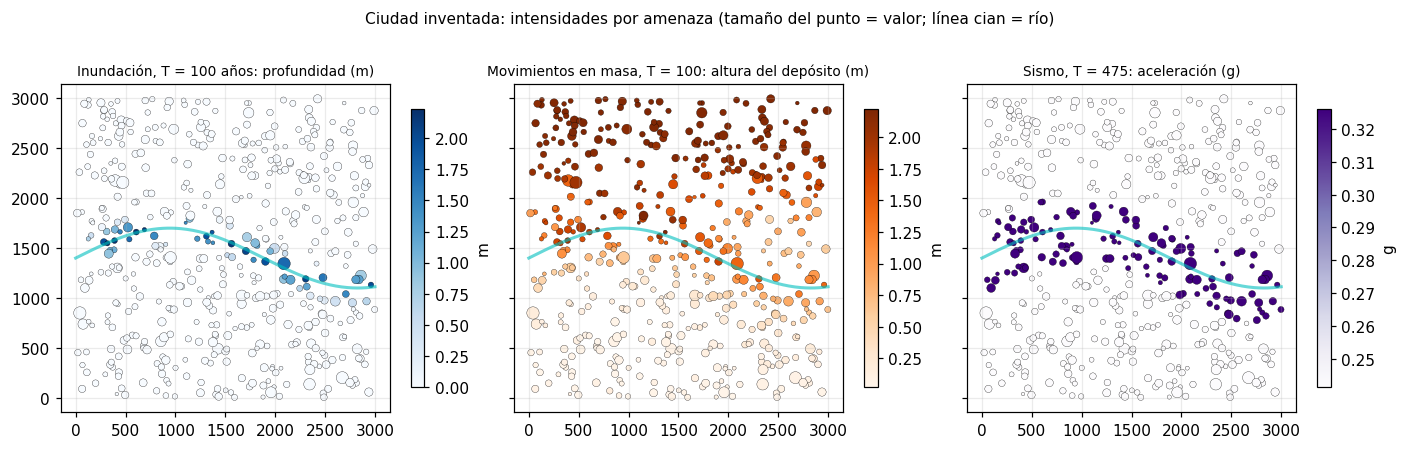

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
for a, (titulo, v, cmap, lab) in zip(ax, [
        ("Inundación, T = 100 años: profundidad (m)", prof, "Blues", "m"),
        ("Movimientos en masa, T = 100: altura del depósito (m)", h, "Oranges", "m"),
        ("Sismo, T = 475: aceleración (g)", perdidas(sismo, 475, "med")[2], "Purples", "g")]):
    s = a.scatter(edif.x, edif.y, c=v, s=edif.valor / 6, cmap=cmap, edgecolor="k", linewidth=0.2)
    xs = np.linspace(0, LADO, 200)
    a.plot(xs, 1400 + 300 * np.sin(xs / 600), "c-", lw=2, alpha=0.6)
    a.set_title(titulo, fontsize=9); a.set_aspect("equal"); plt.colorbar(s, ax=a, shrink=0.7, label=lab)
fig.suptitle("Ciudad inventada: intensidades por amenaza (tamaño del punto = valor; línea cian = río)", fontsize=10)
plt.tight_layout(); plt.show()

## 4. Pérdida por escenario: máximo por elemento dentro del detonante

Para cada escenario de lluvia se calcula la pérdida de cada edificación por inundación y por movimientos en masa. Una misma casa puede ser dañada por ambas durante el mismo evento. Chen et al. (2016) toman **la mayor pérdida por elemento, no la suma**, y además la pérdida no puede superar el valor de la casa. Más abajo se compara con la suma ingenua para ver cuánto se sobrestimaría.

In [6]:
def tabla_escenarios():
    filas = []
    for caso in CASOS:
        for T in T_LLUVIA:
            Li, Ai, _ = perdidas(inundacion, T, caso)
            Lm, Am, _ = perdidas(movimiento_masa, T, caso)
            valor = edif.valor.values * CASOS[caso]["f_val"]
            filas.append(dict(detonante="lluvia", caso=caso, T=T,
                              inundacion=Li.sum(), mov_masa=Lm.sum(),
                              maximo=np.maximum(Li, Lm).sum(),                         # regla adoptada
                              suma_ingenua=np.minimum(Li + Lm, valor).sum(),           # tope: el valor de la casa
                              afectados=np.maximum(Ai, Am).sum()))
        for T in T_SISMO:
            Ls, As, _ = perdidas(sismo, T, caso)
            filas.append(dict(detonante="sismo", caso=caso, T=T, inundacion=np.nan, mov_masa=np.nan,
                              maximo=Ls.sum(), suma_ingenua=Ls.sum(), afectados=As.sum()))
    return pd.DataFrame(filas)

esc = tabla_escenarios()
esc[(esc.caso == "med")].round(0).set_index(["detonante", "T"])[["inundacion", "mov_masa", "maximo", "suma_ingenua", "afectados"]]

inundacion  mov_masa   maximo  suma_ingenua  afectados
detonante T                                                           
lluvia    2           51.0      56.0    106.0         108.0        8.0
          5          212.0     496.0    685.0         708.0       49.0
          10         424.0    1378.0   1718.0        1802.0      114.0
          25         857.0    3484.0   4057.0        4341.0      205.0
          50        1334.0    5740.0   6513.0        7072.0      292.0
          100       1980.0    8465.0   9483.0       10391.0      398.0
          250       3055.0   12687.0  14058.0       15474.0      569.0
          500       3977.0   16335.0  17928.0       19636.0      706.0
sismo     50           NaN       NaN    194.0         194.0       13.0
          100          NaN       NaN   1183.0        1183.0       80.0
          250          NaN       NaN   6695.0        6695.0      454.0
          475          NaN       NaN  15067.0       15067.0     1025.0
          975          NaN       NaN  26752.0       26752.0     1727.0
          2475         NaN       NaN  37977.0       37977.0     2083.0

## 5. Curvas de riesgo y pérdida anual esperada (PAE)

La probabilidad anual de cada escenario es $1/T$. La curva de riesgo grafica la pérdida contra esa probabilidad, y el área bajo la curva es la PAE. Como en CCDR-tools, se calculan dos cotas con sumas de rectángulos (inferior y superior) y se informa también el promedio. La PAE solo cubre el rango de probabilidades de los escenarios dados: **no se estima la cola** de eventos más raros que el mayor escenario.

In [7]:
def pae(T, perdida, f_T=1.0):
    """PAE con cotas inferior y superior (sumas de rectángulos entre escenarios consecutivos)."""
    p = 1 / (np.asarray(T) * f_T)                  # probabilidad anual de excedencia
    orden = np.argsort(-p)
    p, L = p[orden], np.asarray(perdida)[orden]    # p decreciente, pérdida creciente
    dp = p[:-1] - p[1:]
    inf = np.sum(L[:-1] * dp)
    sup = np.sum(L[1:] * dp)
    return inf, sup, (inf + sup) / 2

resumen = []
for det, Ts in [("lluvia", T_LLUVIA), ("sismo", T_SISMO)]:
    for caso in CASOS:
        sub = esc[(esc.detonante == det) & (esc.caso == caso)].sort_values("T")
        inf, sup, med = pae(sub["T"].values, sub["maximo"].values, CASOS[caso]["f_T"])
        resumen.append(dict(detonante=det, caso=caso, PAE_inf=inf, PAE_sup=sup, PAE=med,
                            PML_maximo=sub["maximo"].max(), T_PML=int(sub["T"].max())))
resumen = pd.DataFrame(resumen)
resumen.round(1)

,detonante,caso,PAE_inf,PAE_sup,PAE,PML_maximo,T_PML
0,lluvia,mín,110.7,250.6,180.6,9202.1,500
1,lluvia,med,434.6,966.0,700.3,17927.9,500
2,lluvia,máx,1290.3,2799.0,2044.7,28273.6,500
3,sismo,mín,11.9,34.1,23.0,25675.4,2475
4,sismo,med,54.6,133.0,93.8,37976.6,2475
5,sismo,máx,191.5,409.6,300.5,47550.4,2475


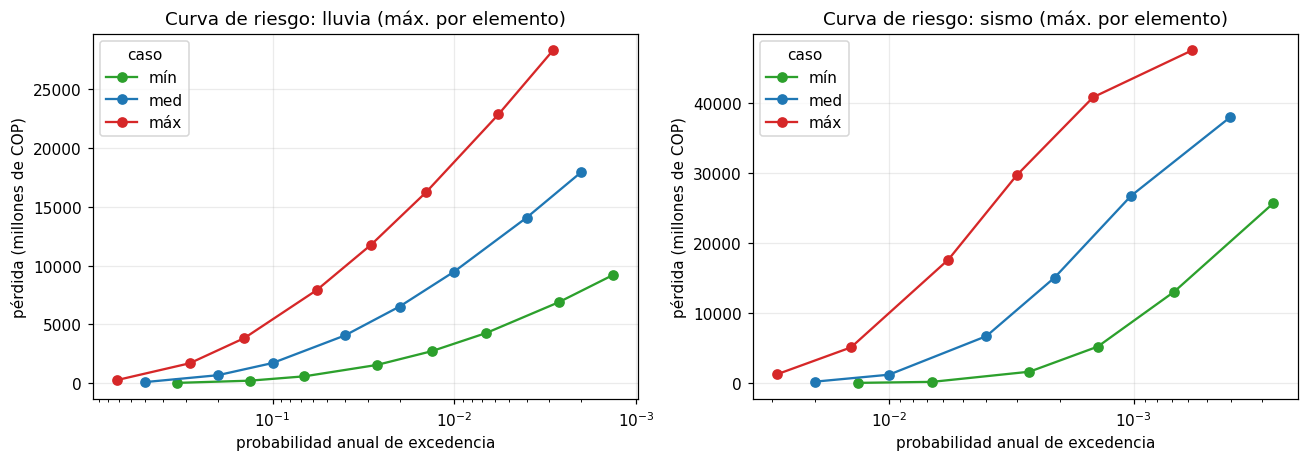

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3), sharey=False)
colores = {"mín": "tab:green", "med": "tab:blue", "máx": "tab:red"}
for a, (det, Ts) in zip(ax, [("lluvia", T_LLUVIA), ("sismo", T_SISMO)]):
    for caso in CASOS:
        sub = esc[(esc.detonante == det) & (esc.caso == caso)].sort_values("T")
        a.plot(1 / (sub["T"] * CASOS[caso]["f_T"]), sub["maximo"], "o-", color=colores[caso], label=caso)
    a.set_xscale("log"); a.invert_xaxis()
    a.set_xlabel("probabilidad anual de excedencia"); a.set_ylabel("pérdida (millones de COP)")
    a.set_title(f"Curva de riesgo: {det} (máx. por elemento)"); a.legend(title="caso")
plt.tight_layout(); plt.show()

Las tres curvas por detonante (mínimo, medio y máximo) son la forma de mostrar la incertidumbre que proponen Chen et al. y que entienden bien quienes toman decisiones. **En un cálculo real el ancho del rango es un resultado importante**: si es muy grande, conviene gastar esfuerzo en reducir la incertidumbre del factor que más pesa antes de decidir.

## 6. ¿Cuánto se sobrestima si se suman amenazas del mismo detonante?

Se compara la regla del máximo con la suma ingenua de inundación y movimientos en masa (con tope en el valor de la casa). El efecto sobre el total depende de **cuánta exposición se solapa**: aquí solo la franja ribereña recibe daño de las dos amenazas, así que el error total es pequeño, pero en esa franja es grande. En una ciudad con más solapamiento (por ejemplo, un valle estrecho con laderas a ambos lados) el error total sería mayor.

In [9]:
comp = []
for caso in CASOS:
    sub = esc[(esc.detonante == "lluvia") & (esc.caso == caso)].sort_values("T")
    f = CASOS[caso]["f_T"]
    comp.append(dict(caso=caso,
                     PAE_maximo=pae(sub["T"].values, sub["maximo"].values, f)[2],
                     PAE_suma_ingenua=pae(sub["T"].values, sub["suma_ingenua"].values, f)[2]))
comp = pd.DataFrame(comp)
comp["sobrestimación (%)"] = 100 * (comp.PAE_suma_ingenua / comp.PAE_maximo - 1)
print("PAE de la lluvia (millones de COP/año):")
display(comp.round(2))

# ¿Dónde se concentra la sobrestimación? En las edificaciones con daño por las dos amenazas a la vez.
Li, _, _ = perdidas(inundacion, 100, "med")
Lm, _, _ = perdidas(movimiento_masa, 100, "med")
doble = (Li > 0) & (Lm > 0)
v = edif.valor.values
max_d, suma_d = np.maximum(Li, Lm)[doble].sum(), np.minimum(Li + Lm, v)[doble].sum()
print(f"Escenario T = 100: {doble.sum()} de {N} edificaciones ({100*doble.mean():.0f} %) sufren daño doble.")
print(f"En ese grupo la suma ingenua sobrestima la pérdida en {100*(suma_d/max_d-1):.0f} %; "
      f"en toda la ciudad, en {100*(np.minimum(Li+Lm,v).sum()/np.maximum(Li,Lm).sum()-1):.1f} %.")

PAE de la lluvia (millones de COP/año):


,caso,PAE_maximo,PAE_suma_ingenua,sobrestimación (%)
0,mín,180.64,189.19,4.73
1,med,700.31,746.22,6.56
2,máx,2044.68,2200.53,7.62


Escenario T = 100: 64 de 500 edificaciones (13 %) sufren daño doble.
En ese grupo la suma ingenua sobrestima la pérdida en 39 %; en toda la ciudad, en 9.6 %.


## 7. Síntesis: qué se suma y qué no

- La **PAE** de detonantes independientes (lluvia y sismo) **se suma**: es un valor esperado en la misma unidad, sobre el mismo inventario.
- La **PML no se suma**: la pérdida del escenario de 500 años de lluvia y la del escenario de 475 años del sismo no ocurren en el mismo año. Si los dos detonantes son independientes, la probabilidad de que ambos ocurran el mismo año es el producto de las probabilidades.

In [10]:
total = resumen.groupby("caso")[["PAE_inf", "PAE_sup", "PAE"]].sum().loc[["mín", "med", "máx"]]
print("PAE total de la ciudad inventada (millones de COP por año), suma de detonantes independientes:")
display(total.round(1))
valor_total = edif.valor.sum()
print(f"Como proporción del valor expuesto ({valor_total:,.0f}): PAE media = {1000 * total.loc['med', 'PAE'] / valor_total:.1f} ‰ por año "
      f"(rango {1000 * total.loc['mín', 'PAE'] / valor_total:.1f} a {1000 * total.loc['máx', 'PAE'] / valor_total:.1f} ‰).")

pml_lluvia = resumen[(resumen.detonante == "lluvia") & (resumen.caso == "med")].PML_maximo.item()
pml_sismo = resumen[(resumen.detonante == "sismo") & (resumen.caso == "med")].PML_maximo.item()
p_conjunta = (1 / 500) * (1 / 2475)
print(f"\nPML lluvia (T=500): {pml_lluvia:,.0f}   PML sismo (T=2475): {pml_sismo:,.0f}")
print(f"Sumarlas daría {pml_lluvia + pml_sismo:,.0f}, pero ambos eventos en un mismo año tienen "
      f"probabilidad {p_conjunta:.1e} (periodo de retorno conjunto ≈ {1/p_conjunta:,.0f} años).")
print("La suma no representa ninguna pérdida de periodo de retorno conocido: se reporta cada PML por separado.")

PAE total de la ciudad inventada (millones de COP por año), suma de detonantes independientes:


,PAE_inf,PAE_sup,PAE
caso,,,
mín,122.7,284.7,203.7
med,489.2,1099.0,794.1
máx,1481.8,3208.6,2345.2


Como proporción del valor expuesto (60,941): PAE media = 13.0 ‰ por año (rango 3.3 a 38.5 ‰).

PML lluvia (T=500): 17,928   PML sismo (T=2475): 37,977
Sumarlas daría 55,905, pero ambos eventos en un mismo año tienen probabilidad 8.1e-07 (periodo de retorno conjunto ≈ 1,237,500 años).
La suma no representa ninguna pérdida de periodo de retorno conocido: se reporta cada PML por separado.


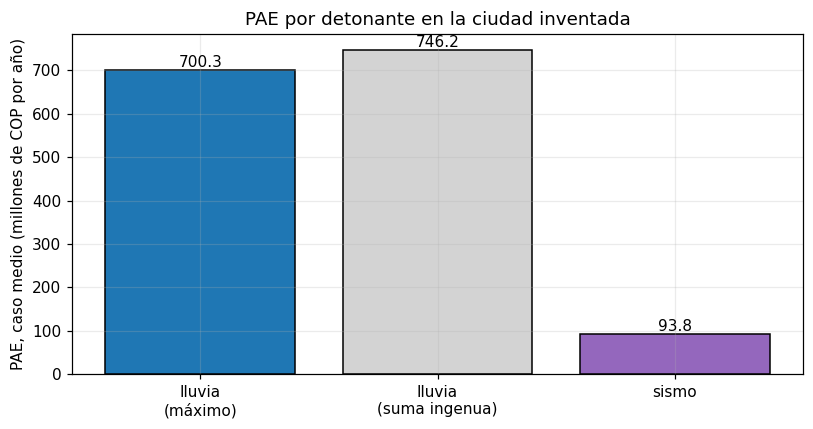

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4))
etiquetas = ["lluvia\n(máximo)", "lluvia\n(suma ingenua)", "sismo"]
med_l = resumen[(resumen.detonante == "lluvia") & (resumen.caso == "med")].PAE.item()
med_s = resumen[(resumen.detonante == "sismo") & (resumen.caso == "med")].PAE.item()
valores = [med_l, comp[comp.caso == "med"].PAE_suma_ingenua.item(), med_s]
ax.bar(etiquetas, valores, color=["tab:blue", "lightgray", "tab:purple"], edgecolor="k")
ax.set_ylabel("PAE, caso medio (millones de COP por año)")
ax.set_title("PAE por detonante en la ciudad inventada")
for i, v in enumerate(valores):
    ax.text(i, v, f"{v:,.1f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 8. Cómo pasar a datos reales

Cada bloque de este cuaderno tiene un equivalente real. Lo que se reemplaza y de dónde sale:

| En este cuaderno | En un análisis real | Dónde se explica |
|---|---|---|
| `edif` con puntos aleatorios | Catastro o censo de edificaciones (GeoPackage), con tipo, valor y ocupantes por edificación | [Exposición](../04_vulnerabilidad/41_exposicion.md) |
| `elev`, `pendiente`, `suscept` | Modelo de elevación, mapa de susceptibilidad (SGC, POT) y mapas de inundación por periodo de retorno | [Movimientos en masa](304_mov_masa.md), [Inundación](305_inundacion.md) |
| `T_LLUVIA`, escenarios de $T$ | Distribución de valores extremos (GEV) ajustada a series del IDEAM | [Probabilista y PAE](../02_metodologia/22_probabilista_pae.md) |
| `inundacion`, `movimiento_masa`, `sismo` | Funciones de daño de la literatura, de expertos o de daños históricos | [Funciones de daño](../04_vulnerabilidad/42_funciones_dano.md) |
| `CASOS` | Rangos justificados para cada factor | [Riesgos multiamenaza](../01_conceptos/14_riesgo_multiamenaza.md) |

El paso más delicado es **definir qué amenazas comparten detonante**: de eso depende dónde se aplica el máximo y dónde se suma. Los eventos que además se disparan unos a otros (cascadas) se tratan en el [cuaderno siguiente](313_riesgos_cascada.ipynb).